# MCP 구조와 capability 협상

**이 노트북에서 할 일**

1. 서버 파일을 읽어 MCP 서버에 메모리로 연결하고, 협상으로 정해진 판 번호와 기능 목록을 봅니다.
2. 서버가 내놓는 도구·자료·메시지 틀 목록을 받고, 셋을 한 번씩 써 봅니다.
3. 인자 `mode` 하나만 바꿔 옛 판 방식으로 다시 연결하고, 두 협상 결과를 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
출력은 모두 서버와 클라이언트가 주고받은 값이라, 다시 실행해도 같은 값이 나와야 합니다.

서버는 실습 폴더 맨 위의 `course_server.py` 파일에 있습니다.
노트북은 이 파일을 읽기만 하고, 쓰는 파일은 없습니다.
서버를 다른 프로그램으로 띄우지 않고, 같은 노트북 안에서 메모리로 연결합니다.
그래서 네트워크와 포트를 쓰지 않습니다.

걸린 시간은 재지 않았습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
판은 fastmcp 4.0.3과 mcp 2.2.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
서버에 붙어 판 번호와 기능 목록, 구성 요소 셋을 보는 자리입니다.
5·6절은 값 하나를 바꿔 견주는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 서버 파일 course_server.py 함수 셋과 서버 객체 mcp에서 파란 상자 runpy.run_path 서버 객체 교육센터 자료실로, 다시 파란 상자 Client server 같은 노트북 안 메모리 연결로 화살표가 갑니다. 그 아래에 서버가 내놓은 구성 요소 셋이라는 칸이 있고, 칸 안에 노란 상자 셋 도구 tools lookup_policy, 자료 resources policy://handbook, 메시지 틀 prompts explain_policy가 위에서 아래로 나란히 놓인 그림](attachment:01-1-서버와-구성-요소-셋.png)

위에서 아래로 읽습니다.
초록 상자는 실습 폴더의 서버 파일이고, 파란 상자 둘은 노트북 2·3절에서 우리가 부른 코드입니다.
칸 안 노란 상자 셋은 4절 출력으로 확인한 이름이고, 서로 다른 종류라 화살표 없이 나란히 두었습니다.
서버는 다른 프로그램으로 띄우지 않고, 같은 노트북 안에서 메모리로 연결했습니다.
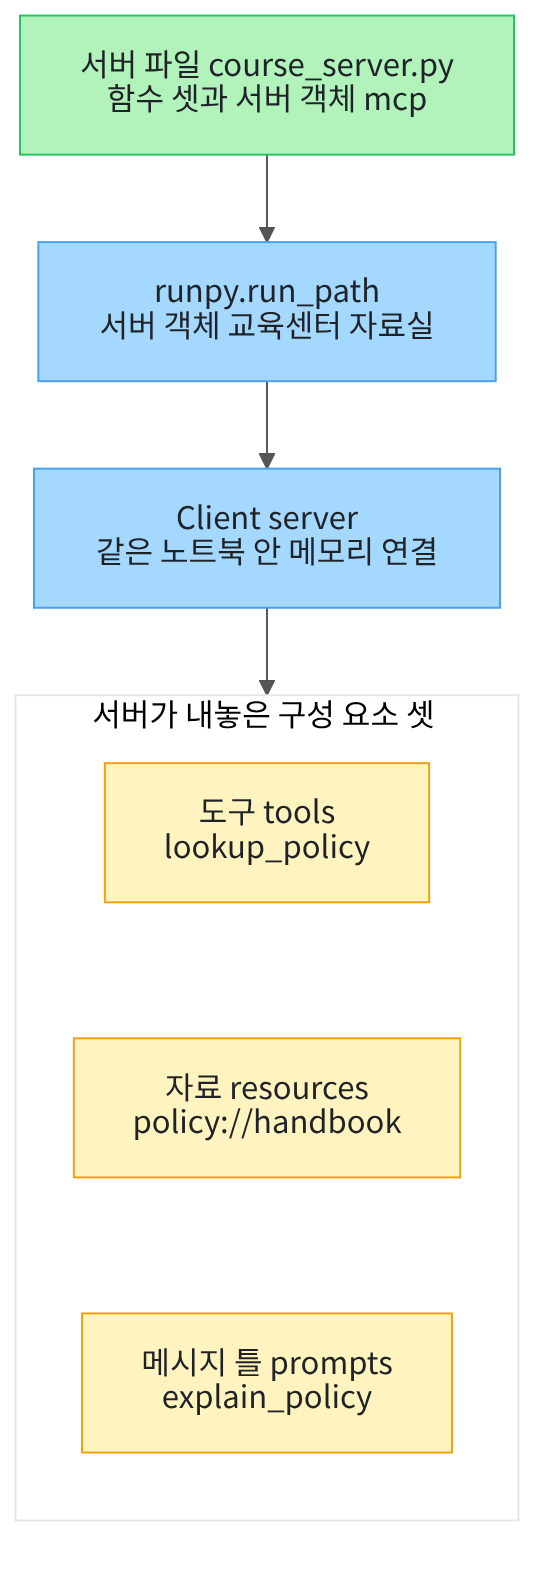

## 1. 준비

모델이 쓸 도구와 자료를 다른 프로그램에서 가져오는 약속이 MCP(Model Context Protocol)입니다.
이 절은 MCP 서버에 처음 붙어 보고, 서버가 무엇을 알리는지 출력으로 봅니다.
뜻과 구성은 본문 「핵심 개념」에서 풉니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastmcp==4.0.3" "mcp==2.2.0"
from importlib.metadata import version

print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))

Note: you may need to restart the kernel to use updated packages.


fastmcp: 4.0.3
mcp: 2.2.0


**결과 읽기** — 출력 줄 `fastmcp: 4.0.3`과 `mcp: 2.2.0`이 보입니다.
둘 다 실습 폴더 잠금과 같은 판입니다.
패키지 fastmcp는 MCP 서버와 클라이언트를 만드는 라이브러리입니다.
패키지 mcp는 MCP의 공식 파이썬 도구 모음이고, fastmcp가 안에서 씁니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `json`·`os`·`runpy`는 Python에 들어 있는 모듈입니다.
클라이언트 `Client`와 서버 `FastMCP`는 패키지 fastmcp에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(json·os·runpy는 Python에 들어 있는 모듈입니다)
import json
import os
import runpy
from fastmcp import Client, FastMCP

print("가져온 FastMCP 이름:", "Client, FastMCP")

가져온 FastMCP 이름: Client, FastMCP


**결과 읽기** — 출력 줄 `가져온 FastMCP 이름: Client, FastMCP`가 보입니다.
서버 클래스 `FastMCP`는 6절에서 빈 서버를 하나 만들 때 씁니다.
이 노트북에는 API 키를 확인하는 셀이 없습니다.
모델을 부르지 않기 때문입니다.

## 2. 서버 파일 읽기

이 챕터의 서버는 실습 폴더 맨 위 파일 `course_server.py`에 있습니다.
노트북을 어디서 열었는지에 따라 이 파일을 가리키는 글이 달라집니다.
다음 셀은 Ch 10 01절의 파일 위치 셀처럼 후보 셋을 차례로 보고, 처음 있는 것을 고릅니다.
함수 `os.path.exists`는 그 위치에 파일이 있으면 `True`를 내놓습니다.

In [3]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 이 파일을 실행해 서버 객체를 얻습니다.
함수 `runpy.run_path`는 파이썬 파일 하나를 실행하고, 그 파일이 만든 이름을 딕셔너리로 내놓습니다.
서버 파일 맨 끝의 `if __name__ == "__main__":` 아래 줄은 그 파일을 직접 실행할 때만 돕니다.
이 함수로 읽으면 그 줄이 돌지 않아, 서버가 따로 떠 있지 않습니다.

In [4]:
# 서버 파일을 실행해, 그 파일이 만든 이름을 딕셔너리로 받습니다
server_names = runpy.run_path(server_file)
# 서버 파일이 만든 서버 객체의 이름은 mcp입니다
server = server_names["mcp"]
print("서버 객체 종류:", type(server).__name__)
print("서버 이름:", server.name)

서버 객체 종류: FastMCP
서버 이름: 교육센터 자료실


**결과 읽기** — 출력 줄 `서버 객체 종류: FastMCP`와 `서버 이름: 교육센터 자료실`이 보입니다.
서버 이름은 서버 파일이 클래스 `FastMCP`에 처음 넘긴 글입니다.
함수 `runpy.run_path`는 파일을 읽을 때 컴파일한 파일(`.pyc`)을 실습 폴더에 남기지 않습니다.

다음 셀은 이 파일이 만든 이름을 봅니다.
밑줄 둘로 시작하는 이름(`__name__` 등)은 Python이 채운 것이라 뺍니다.

In [5]:
# 파일이 만든 이름 가운데 밑줄 둘로 시작하지 않는 것만 모읍니다
file_names = []
for name in server_names:
    if not name.startswith("__"):
        file_names.append(name)
print("파일이 만든 이름:", file_names)
print("lookup_policy의 종류:", type(server_names["lookup_policy"]).__name__)

파일이 만든 이름: ['FastMCP', 'POLICIES', 'mcp', 'lookup_policy', 'policy_handbook', 'explain_policy']
lookup_policy의 종류: function


**결과 읽기** — 라벨 `파일이 만든 이름:` 뒤에 `'lookup_policy'`·`'policy_handbook'`·`'explain_policy'`가 있습니다.
이 세 함수를 서버 파일이 서버에 붙였고, 붙이는 줄(`@mcp.tool` 등)은 02절에서 배웁니다.
출력 줄 `lookup_policy의 종류: function`처럼, 붙인 뒤에도 파일 안에서는 평범한 함수입니다.
이 절에서는 이 함수를 직접 부르지 않고, 클라이언트를 거쳐 서버에 요청합니다.

## 3. 기본 모드로 연결하기

MCP에서 서버에 요청을 보내는 쪽을 클라이언트라고 부릅니다.
클래스 `Client`에 서버 객체를 넘기면, 같은 노트북 안에서 메모리로 붙는 클라이언트가 됩니다.
MCP 클라이언트의 메서드는 모두 비동기이고, 결과가 올 때까지 기다리며 씁니다.

다음 셀의 첫 줄 `async with`는 Ch 2 05절의 `with open(...)`처럼, 블록을 벗어날 때 연결을 닫는 줄입니다.
연결을 열고 닫는 일도 기다려야 해서 앞에 `async`를 붙입니다.
Ch 18 03절에서 본 것처럼, 셀 맨 위에 `async with`나 await 줄을 바로 쓰는 것은 노트북 도구(IPython)의 기능입니다.
파이썬 파일에서는 Ch 2 12절처럼 `async def` 함수 안에 넣고 `asyncio.run()`으로 부릅니다.
노트북 셀에서는 `asyncio.run()`을 쓰지 않습니다.

노트북은 이미 비동기 실행을 돌리고 있어서, 셀에서 부르면 `RuntimeError`가 나기 때문입니다.
이 오류는 따로 만든 작은 노트북에서 확인했고, 이 노트북에서는 실행하지 않습니다.

In [6]:
# 클라이언트로 서버에 연결하고, 협상으로 정해진 판 번호를 봅니다
async with Client(server) as client:
    auto_version = client.protocol_version
print("인자 mode의 값:", client.mode)
print("정해진 판 번호:", auto_version)
# 블록을 벗어난 뒤에 같은 속성을 다시 읽어 봅니다
print("블록 밖에서 본 판 번호:", client.protocol_version)
print("블록 밖에서 연결되어 있는가:", client.is_connected())

인자 mode의 값: auto
정해진 판 번호: 2026-07-28
블록 밖에서 본 판 번호: None
블록 밖에서 연결되어 있는가: False


**결과 읽기** — 출력 줄 `인자 mode의 값: auto`와 `정해진 판 번호: 2026-07-28`이 보입니다.
인자 `mode`를 주지 않으면 기본값 `auto`가 쓰입니다.
판 번호는 두 쪽이 어느 판의 약속으로 말할지 정한 값이고, MCP 규격 문서의 날짜 이름입니다.
블록 밖에서는 판 번호가 `None`이고, 연결되어 있는가가 `False`입니다.
블록을 벗어나면서 연결이 닫혔기 때문입니다.

2026-09-28에 확인한 MCP 규격 문서는 2026-07-28을 현재 판으로 적습니다.
기본 모드는 연결하자마자 서버에 `server/discover` 요청을 먼저 보내, 서버가 이 판을 쓰는지 묻습니다.
이 요청 이름은 설치판 fastmcp 4.0.3 소스와 노트북 밖 확인으로 본 것이고, 노트북에는 출력하지 않습니다.

다음 셀은 협상 결과를 한국어 키 딕셔너리로 모으는 함수를 만듭니다.
속성 `initialize_result`는 옛 판 방식의 첫 요청 `initialize`에 서버가 준 응답입니다.
속성 `server_info`는 서버가 밝힌 이름과 판, 속성 `instructions`는 서버가 붙인 사용 설명 글입니다.

In [7]:
# 연결된 클라이언트에서 협상 결과를 읽어, 한국어 키 딕셔너리로 내놓습니다
def read_negotiation(client):
    row = {
        "판 번호": client.protocol_version,
        "초기화 결과가 있는가": client.initialize_result is not None,
        "서버 이름": client.server_info.name,
        "서버 판": client.server_info.version,
        "사용 설명": client.instructions,
    }
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키 「초기화 결과가 있는가」는 속성 `initialize_result`가 `None`이 아니면 `True`입니다.
블록 안에서 불러야 값이 채워져 있습니다.

다음 셀은 기본 모드로 다시 연결해, 협상 결과와 서버가 알린 기능 목록(capabilities)을 함께 받아 둡니다.
연결마다 협상을 새로 하므로, 앞 셀의 연결은 다시 쓰지 않습니다.
메서드 `model_dump`는 라이브러리의 값 객체를 딕셔너리로 바꿉니다.
인자 `exclude_none=True`는 값이 없는 칸을 빼고, `by_alias=True`는 칸 이름을 규격 문서의 이름으로 씁니다.

In [8]:
# 기본 모드로 다시 연결해, 협상 결과와 서버가 알린 기능 목록을 받아 둡니다
async with Client(server) as client:
    auto_row = read_negotiation(client)
    # model_dump는 기능 목록 객체를 딕셔너리로 바꿉니다(값이 없는 칸은 빼고, 칸 이름은 규격 문서 이름으로)
    auto_caps = client.server_capabilities.model_dump(exclude_none=True, by_alias=True)
print("기본 모드 협상 결과:")
print(auto_row)

기본 모드 협상 결과:
{'판 번호': '2026-07-28', '초기화 결과가 있는가': False, '서버 이름': '교육센터 자료실', '서버 판': '4.0.3', '사용 설명': '공개된 자료실 규정을 읽기 전용으로 제공합니다.'}


**결과 읽기** — 라벨 줄 아래 딕셔너리에 `'판 번호': '2026-07-28'`과 `'초기화 결과가 있는가': False`가 보입니다.
서버 이름은 `'교육센터 자료실'`이고, 키 `'서버 판': '4.0.3'`도 있습니다.
키 「사용 설명」은 서버 파일이 인자 `instructions`에 적은 글입니다.

서버 판 4.0.3은 fastmcp 자신의 판 번호입니다.
서버 파일이 판을 정하지 않아, 설치판 fastmcp가 자기 판 번호를 채웠습니다.

다음 셀은 받아 둔 기능 목록을 JSON 글로 바꿔 봅니다.
함수 `json.dumps`의 인자 `sort_keys=True`는 키를 알파벳 차례로 늘어놓습니다.

In [9]:
# 기본 모드에서 받은 기능 목록을 JSON 글로 바꿔 출력합니다(키는 알파벳 차례)
auto_caps_text = json.dumps(auto_caps, ensure_ascii=False, sort_keys=True)
print("기본 모드 기능 목록:")
print(auto_caps_text)

기본 모드 기능 목록:
{"extensions": {"io.modelcontextprotocol/ui": {}}, "logging": {}, "prompts": {"listChanged": false}, "resources": {"listChanged": false, "subscribe": false}, "tools": {"listChanged": false}}


**결과 읽기** — 라벨 줄 아래 JSON 글에 키 `"tools"`·`"resources"`·`"prompts"`가 있습니다.
서버가 도구·자료·메시지 틀 요청을 받는다는 알림입니다.
셋 모두 안쪽 칸이 `"listChanged": false`입니다.

칸 `listChanged`는 목록이 바뀌면 알려 주겠다는 표시입니다.
현재 판에서 이 알림은 따로 여는 알림 연결(`subscriptions/listen`)로만 갑니다.
설치판 mcp 2.2.0은 서버가 그 요청을 받을 때만 이 값을 채우고, fastmcp 4.0.3 서버는 받지 않아 `false`입니다.

키 `"logging"`은 기록 기능, `"extensions"`는 핵심 규약 밖 추가 기능(확장)의 알림입니다.
칸 `extensions`는 현재 판에 새로 생긴 칸입니다.
안의 `io.modelcontextprotocol/ui`는 도구·자료에 화면 정보를 싣는 확장의 이름이고, 설치판 fastmcp가 늘 알립니다.
현재 판 변경 목록은 기록 기능을 더 쓰지 말라고 표시했지만, 설치판 서버는 칸 `logging`을 그대로 알립니다.
알림과 기록을 실제로 받는 장면은 이 절에서 실행하지 않았습니다.

## 4. 구성 요소 셋 받아 쓰기

기능 목록은 어떤 종류의 요청을 받는지만 알립니다.
서버에 실제로 무엇이 있는지는 목록 요청으로 받습니다.
도구 목록은 메서드 `list_tools`, 자료 목록은 `list_resources`, 메시지 틀 목록은 `list_prompts`로 받습니다.
세 메서드 모두 await로 기다립니다.

In [10]:
# 같은 서버에 연결해 도구·자료·메시지 틀 목록을 받습니다
async with Client(server) as client:
    tools = await client.list_tools()
    resources = await client.list_resources()
    prompts = await client.list_prompts()
print("받은 도구 수:", len(tools))
print("받은 자료 수:", len(resources))
print("받은 메시지 틀 수:", len(prompts))

받은 도구 수: 1
받은 자료 수: 1
받은 메시지 틀 수: 1


**결과 읽기** — 출력 줄 `받은 도구 수: 1`, `받은 자료 수: 1`, `받은 메시지 틀 수: 1`이 보입니다.
서버 파일의 함수 셋이 한 종류에 하나씩 붙어 있습니다.

다음 셀은 목록의 항목마다 이름 칸 `name`을 모으는 함수를 만듭니다.
세 목록의 항목은 모두 이름 칸을 가집니다.

In [11]:
# 목록의 항목마다 이름 칸 name을 모아 내놓습니다
def names_of(items):
    names = []
    for item in items:
        names.append(item.name)
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
빈 목록을 받으면 빈 목록을 내놓고, 이 모양은 6절에서 다시 봅니다.

다음 셀은 세 목록의 이름과, 자료를 읽을 때 쓰는 주소를 봅니다.
자료는 이름과 함께 주소(URI)를 가집니다.

In [12]:
# 세 목록의 이름과, 자료를 읽을 때 쓰는 주소를 봅니다
print("도구 이름:", names_of(tools))
print("자료 이름:", names_of(resources))
print("메시지 틀 이름:", names_of(prompts))
print("자료 주소:", str(resources[0].uri))

도구 이름: ['lookup_policy']
자료 이름: ['policy_handbook']
메시지 틀 이름: ['explain_policy']
자료 주소: policy://handbook


**결과 읽기** — 출력 줄 `도구 이름: ['lookup_policy']`와 `메시지 틀 이름: ['explain_policy']`가 보입니다.
자료 이름은 함수 이름 `policy_handbook`이고, 주소는 `policy://handbook`입니다.
주소는 서버 파일에서 자료 함수를 붙이는 줄에 적은 글입니다.

다음 셀은 도구 정의 하나를 들여다봅니다.
도구 정의에는 이름·설명과 함께 인자의 입력 형식(Ch 19 01절)이 들어 있습니다.
모델에게 도구를 알려 줄 때 쓰는 정보이고, 04·05절에서 다시 씁니다.

In [13]:
# 도구 정의 하나에서 설명과 입력 형식을 봅니다
tool = tools[0]
print("도구 설명:", tool.description)
print("입력 형식:", tool.input_schema)

도구 설명: 자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다.
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {'topic': {'type': 'string'}}, 'required': ['topic']}


**결과 읽기** — 라벨 `도구 설명:` 뒤에 서버 파일 함수의 독스트링 글이 보입니다.
라벨 `입력 형식:` 뒤에는 `'required': ['topic']`과 `'topic': {'type': 'string'}`이 있습니다.
인자 `topic`이 꼭 있어야 하고, 글이어야 한다는 뜻입니다.

이 입력 형식은 서버 파일 함수의 매개변수 힌트 `topic: str`에서 만들어졌고, 02절에서 자세히 봅니다.
칸 `'additionalProperties': False`는 정해 두지 않은 인자를 받지 않는다는 뜻입니다.

다음 셀부터는 구성 요소 셋을 한 번씩 씁니다.
먼저 도구를 부릅니다.
메서드 `call_tool`에 도구 이름과 인자 딕셔너리를 넘기면, 서버가 도구 함수를 실행한 결과를 내놓습니다.

In [14]:
# 도구 lookup_policy를 부르고, 서버가 내놓은 결과를 봅니다
async with Client(server) as client:
    tool_result = await client.call_tool("lookup_policy", {"topic": "대출"})
print("결과 종류:", type(tool_result).__name__)
print("오류인가:", tool_result.is_error)
# 결과의 칸 content는 내용 블록의 목록이고, 첫 블록의 칸 text가 글입니다
print("결과 글:", tool_result.content[0].text)

결과 종류: CallToolResult
오류인가: False
결과 글: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.


**결과 읽기** — 출력 줄 `결과 종류: CallToolResult`와 `오류인가: False`가 보입니다.
라벨 `결과 글:` 뒤에는 서버 파일에 적힌 대출 규정 한 문장이 있습니다.
서버가 함수 `lookup_policy`를 실행하고, 그 결과를 내용 블록에 담아 보냈습니다.

다음 셀은 자료를 읽습니다.
메서드 `read_resource`에 자료의 주소를 넘기면, 서버가 자료 함수를 실행한 글을 내놓습니다.
결과는 읽은 내용의 목록입니다.

In [15]:
# 자료를 주소로 읽고, 읽은 글을 봅니다
async with Client(server) as client:
    contents = await client.read_resource("policy://handbook")
print("읽은 내용 수:", len(contents))
print("읽은 글:")
print(contents[0].text)

읽은 내용 수: 1
읽은 글:
대출: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
운영: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.
연체: 연체한 일수만큼 새 대출이 제한됩니다.


**결과 읽기** — 출력 줄 `읽은 내용 수: 1`이 보입니다.
라벨 `읽은 글:` 아래에 대출·운영·연체 규정 세 줄이 있습니다.
도구는 인자를 받아 실행하는 기능이고, 자료는 주소로 읽는 글입니다.

다음 셀은 메시지 틀을 받습니다.
메서드 `get_prompt`에 틀 이름과 빈자리에 넣을 값을 넘깁니다.
Ch 7 04절에서 쓴 틀과 빈자리와 같은 생각입니다.

In [16]:
# 메시지 틀 explain_policy의 빈자리에 주제를 넣어 받고, 만들어진 메시지를 봅니다
async with Client(server) as client:
    prompt_result = await client.get_prompt("explain_policy", {"topic": "대출"})
first_message = prompt_result.messages[0]
print("메시지 수:", len(prompt_result.messages))
print("메시지 역할:", first_message.role)
print("메시지 글:", first_message.content.text)

메시지 수: 1
메시지 역할: user
메시지 글: 대출 규정을 근거 문장과 함께 두 문장으로 설명해 주세요.


**결과 읽기** — 출력 줄 `메시지 수: 1`과 `메시지 역할: user`가 보입니다.
라벨 `메시지 글:` 뒤에 주제 「대출」이 빈자리에 들어간 요청 글이 있습니다.
서버는 메시지를 만들어 주기만 하고, 이 절은 그 메시지를 모델에게 보내지 않습니다.

## 5. 값 바꿔 보기: 옛 판 모드로 연결하기

값 하나만 바꿔 봅니다.
바꿀 값은 클래스 `Client`의 인자 `mode`이고, 값 `"legacy"`를 넣습니다.
이 모드는 2025-11-25 판까지 쓰던 방식으로, 연결하자마자 `initialize` 요청과 응답을 먼저 주고받습니다.
실행 전에 예상해 봅니다.
판 번호와 키 「초기화 결과가 있는가」는 바뀔까요, 세 목록도 바뀔까요?

In [17]:
# 인자 mode 하나만 "legacy"로 바꿔 연결하고, 협상 결과와 기능 목록을 받아 둡니다
async with Client(server, mode="legacy") as client:
    legacy_row = read_negotiation(client)
    legacy_caps = client.server_capabilities.model_dump(exclude_none=True, by_alias=True)
print("옛 판 모드 협상 결과:")
print(legacy_row)

옛 판 모드 협상 결과:
{'판 번호': '2025-11-25', '초기화 결과가 있는가': True, '서버 이름': '교육센터 자료실', '서버 판': '4.0.3', '사용 설명': '공개된 자료실 규정을 읽기 전용으로 제공합니다.'}


**결과 읽기** — 라벨 줄 아래 딕셔너리에 `'판 번호': '2025-11-25'`와 `'초기화 결과가 있는가': True`가 보입니다.
서버 이름·서버 판·사용 설명은 기본 모드와 같은 글입니다.
옛 판 모드에서는 서버가 `initialize` 요청에 준 응답이 속성 `initialize_result`에 남습니다.

다음 셀은 옛 판 모드의 기능 목록을 봅니다.

In [18]:
# 옛 판 모드에서 받은 기능 목록을 JSON 글로 바꿔 출력합니다(키는 알파벳 차례)
legacy_caps_text = json.dumps(legacy_caps, ensure_ascii=False, sort_keys=True)
print("옛 판 모드 기능 목록:")
print(legacy_caps_text)

옛 판 모드 기능 목록:
{"logging": {}, "prompts": {"listChanged": true}, "resources": {"listChanged": true, "subscribe": false}, "tools": {"listChanged": true}}


**결과 읽기** — 라벨 줄 아래 JSON 글에서 셋 모두 `"listChanged": true`로 바뀌었습니다.
키 `"extensions"`는 없고, `"logging"`은 그대로 있습니다.
칸 `extensions`는 현재 판에 새로 생긴 칸이라, 설치판 SDK가 옛 판 응답에서는 이 칸을 뺍니다.
설치판 fastmcp는 옛 판용으로 세 구성 요소 모두 목록이 바뀌면 알린다고 정해 둡니다.

다음 셀은 두 딕셔너리를 키마다 나란히 출력하는 함수를 만듭니다.

In [19]:
# 두 딕셔너리를 키마다 나란히 출력하고, 두 값이 같은지 적습니다
def compare_rows(first, second):
    for key in first:
        same = first[key] == second[key]
        print(key, "|", first[key], "|", second[key], "|", same)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
첫째 딕셔너리의 키 차례대로, 두 값과 같은지 여부를 한 줄에 적습니다.

다음 셀은 두 모드의 협상 결과를 이 함수로 견줍니다.

In [20]:
# 기본 모드와 옛 판 모드의 협상 결과를 키마다 나란히 봅니다
print("항목 | 기본 모드 | 옛 판 모드 | 같은가")
compare_rows(auto_row, legacy_row)

항목 | 기본 모드 | 옛 판 모드 | 같은가
판 번호 | 2026-07-28 | 2025-11-25 | False
초기화 결과가 있는가 | False | True | False
서버 이름 | 교육센터 자료실 | 교육센터 자료실 | True
서버 판 | 4.0.3 | 4.0.3 | True
사용 설명 | 공개된 자료실 규정을 읽기 전용으로 제공합니다. | 공개된 자료실 규정을 읽기 전용으로 제공합니다. | True


**결과 읽기** — 줄 `판 번호 | 2026-07-28 | 2025-11-25 | False`와 `초기화 결과가 있는가 | False | True | False`가 보입니다.
서버 이름·서버 판·사용 설명의 세 줄은 끝 칸이 `True`입니다.
모드만 바꾸면 판 번호와 첫 요청의 모양이 바뀌고, 서버가 밝힌 정보는 그대로입니다.

다음 셀은 기능 목록에서 구성 요소 셋의 `listChanged` 값과, 추가 기능 칸이 있는지를 모으는 함수를 만듭니다.

In [21]:
# 기능 목록에서 구성 요소 셋의 listChanged 값과, 추가 기능 칸이 있는지를 모아 내놓습니다
def change_flags(caps):
    flags = {
        "tools의 listChanged": caps["tools"]["listChanged"],
        "resources의 listChanged": caps["resources"]["listChanged"],
        "prompts의 listChanged": caps["prompts"]["listChanged"],
        "extensions 칸이 있는가": "extensions" in caps,
    }
    return flags

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기능 목록 딕셔너리에서 키를 두 번 찾아 안쪽 값을 꺼냅니다.

다음 셀은 두 모드의 기능 목록을 이 함수와 앞 함수로 견줍니다.

In [22]:
# 두 모드의 기능 목록에서 모은 값을 나란히 봅니다
auto_flags = change_flags(auto_caps)
legacy_flags = change_flags(legacy_caps)
print("항목 | 기본 모드 | 옛 판 모드 | 같은가")
compare_rows(auto_flags, legacy_flags)

항목 | 기본 모드 | 옛 판 모드 | 같은가
tools의 listChanged | False | True | False
resources의 listChanged | False | True | False
prompts의 listChanged | False | True | False
extensions 칸이 있는가 | True | False | False


**결과 읽기** — 줄 `tools의 listChanged | False | True | False`처럼 구성 요소 셋 모두 기본 모드가 `False`, 옛 판 모드가 `True`입니다.
줄 `extensions 칸이 있는가 | True | False | False`로, 추가 기능 알림은 기본 모드에만 있었습니다.
구성 요소 셋의 칸은 두 모드 모두에 있었습니다.

다음 셀은 옛 판 모드로도 같은 목록과 도구 결과를 받는지 봅니다.

In [23]:
# 옛 판 모드로 다시 연결해 세 목록과 도구 결과를 받습니다
async with Client(server, mode="legacy") as client:
    legacy_tools = await client.list_tools()
    legacy_resources = await client.list_resources()
    legacy_prompts = await client.list_prompts()
    legacy_result = await client.call_tool("lookup_policy", {"topic": "대출"})
print("옛 판 모드 도구 이름:", names_of(legacy_tools))

옛 판 모드 도구 이름: ['lookup_policy']


**결과 읽기** — 출력 줄 `옛 판 모드 도구 이름: ['lookup_policy']`가 보입니다.
다음 셀은 받아 둔 네 값이 기본 모드에서 받은 값과 같은지 견줍니다.

In [24]:
# 두 모드에서 받은 세 목록의 이름과 도구 결과 글이 같은지 봅니다
print("도구 이름이 같은가:", names_of(legacy_tools) == names_of(tools))
print("자료 이름이 같은가:", names_of(legacy_resources) == names_of(resources))
print("메시지 틀 이름이 같은가:", names_of(legacy_prompts) == names_of(prompts))
legacy_text = legacy_result.content[0].text
print("도구 결과 글이 같은가:", legacy_text == tool_result.content[0].text)

도구 이름이 같은가: True
자료 이름이 같은가: True
메시지 틀 이름이 같은가: True
도구 결과 글이 같은가: True


**결과 읽기** — 출력 네 줄이 모두 `True`입니다.
판 번호가 달라도 목록 요청과 도구 요청은 같은 메서드로 보내고, 같은 값을 받았습니다.
모드가 다른 두 클라이언트가 같은 서버를 같은 방법으로 찾은 것입니다.

## 6. 붙인 것이 없는 서버의 기능 목록

기능 목록에 키 `"tools"`가 있다고 도구가 있는 것은 아닙니다.
이것을 보려고, 아무것도 붙이지 않은 서버를 하나 만듭니다.
클래스 `FastMCP`에 서버 이름 하나만 넘기면 서버 객체가 생깁니다.
도구를 붙이는 방법은 02절에서 배웁니다.

실행 전에 예상해 봅니다.
붙인 것이 없으니 기능 목록도 비어 있을까요?

In [25]:
# 아무것도 붙이지 않은 서버를 만들고 기본 모드로 연결해, 기능 목록과 세 목록을 받습니다
empty_server = FastMCP("빈 자료실")
async with Client(empty_server) as client:
    empty_caps = client.server_capabilities.model_dump(exclude_none=True, by_alias=True)
    empty_tools = await client.list_tools()
    empty_resources = await client.list_resources()
    empty_prompts = await client.list_prompts()
print("기능 목록의 키:", sorted(empty_caps))
print("세 목록의 이름:", names_of(empty_tools), names_of(empty_resources), names_of(empty_prompts))

기능 목록의 키: ['extensions', 'logging', 'prompts', 'resources', 'tools']
세 목록의 이름: [] [] []


**결과 읽기** — 라벨 `기능 목록의 키:` 뒤에 `'prompts'`·`'resources'`·`'tools'`가 있습니다.
라벨 `세 목록의 이름:` 뒤는 빈 목록 셋 `[] [] []`입니다.
붙인 것이 없어도 서버는 구성 요소 셋의 요청을 받는다고 알렸습니다.

설치판 mcp 2.2.0 소스에서 서버는 목록 요청을 처리하는 곳이 있으면 그 칸을 채웁니다.
fastmcp 서버는 붙인 것과 상관없이 세 목록 요청을 늘 처리합니다.
그래서 이 서버로는 기능 목록에 없는 요청을 보내는 장면을 만들 수 없습니다.

## 정리

1. 기본 모드는 2026-07-28, 옛 판 모드는 2025-11-25로 연결했고, 초기화 결과는 옛 판에만 있었습니다.
2. 두 모드 모두 서버 정보와 세 목록, 도구 결과가 같았고, `listChanged` 값과 추가 기능 칸만 달랐습니다.
3. 기능 목록은 받는 요청의 종류를 알릴 뿐이고, 붙인 것이 없는 서버도 세 칸을 모두 알렸습니다.

02절에서는 서버에 도구를 붙이는 줄을 직접 쓰고, 붙이는 모양에 따라 입력 형식이 어떻게 달라지는지 봅니다.